# Đề 9 — E-Commerce Customer Segmentation

## Notebook 03 — Phân cụm và Diễn giải

**Đầu vào:** `data/rfm.parquet` (RFM thô) và `data/rfm_scaled.parquet` (đã `log1p` + `StandardScaler`)

**Mục tiêu**

1. Kiểm tra dữ liệu có cấu trúc cụm hay không (clustering tendency)
2. Chọn số cụm $K$ bằng nhiều tiêu chí độc lập
3. Đo và xử lý **ảnh hưởng của outlier tới centroid**
4. Chạy và so sánh ba họ thuật toán: **phân hoạch** (K-Means), **phân cấp** (Agglomerative), **mật độ** (DBSCAN)
5. Đánh giá chất lượng cụm, đặc tả và đặt tên từng phân khúc khách hàng

**Đối chiếu với yêu cầu đề bài**

| Yêu cầu | Mục |
|---|---|
| Handle outliers affecting cluster centroids | 4.3 |
| Apply and compare K-Means and Agglomerative | 4, 5 |
| Select optimal K via Silhouette and Elbow | 3 |
| Profile cluster characteristics | 8 |

**Đầu ra:** `data/clusters.parquet` (nhãn cụm của từng khách) và `data/cluster_profile.csv`

**Nguyên tắc xuyên suốt:** thuật toán chạy trên dữ liệu **đã chuẩn hóa**, nhưng mọi
diễn giải cho người đọc dùng dữ liệu **thô** — vì không ai hiểu "Monetary chuẩn hóa = 1,2" nghĩa là gì.

---

## 0. Thiết lập

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from kneed import KneeLocator
from scipy.cluster.hierarchy import linkage, dendrogram, set_link_color_palette
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (silhouette_score, silhouette_samples,
                             davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score)

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')

DATA         = Path('data')
RFM_IN       = DATA / 'rfm.parquet'
SCALED_IN    = DATA / 'rfm_scaled.parquet'
CLUSTERS_OUT = DATA / 'clusters.parquet'
PROFILE_OUT  = DATA / 'cluster_profile.csv'

COLS = ['Recency', 'Frequency', 'Monetary']
SEED = 42

# Bảng màu phân loại: dùng theo THỨ TỰ CỐ ĐỊNH, cụm i luôn mang màu i.
# Biểu đồ tán xạ chỉ đảm bảo phân biệt được 3 màu đầu cho người mù màu,
# nên mỗi cụm có thêm một hình dạng điểm riêng làm mã hóa phụ.
PALETTE = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100',
           '#e87ba4', '#008300', '#6250d6', '#e34948']
MARKERS = ['o', 's', '^', 'D', 'v', 'P', 'X', '*']
SERIES  = PALETTE[0]   # màu cho biểu đồ chỉ có một chuỗi dữ liệu
INK     = '#5f5e5a'    # màu chữ chú thích, đường tham chiếu


def tidy(ax):
    # Trục gọn: bỏ viền trên/phải, lưới ngang mờ nằm dưới dữ liệu
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(axis='y', alpha=0.25)
    ax.set_axisbelow(True)

---

## 1. Nạp dữ liệu

Hai file được nạp song song và phải khớp nhau từng khách hàng — `rfm` dùng để
diễn giải, `X` dùng để chạy thuật toán.

In [2]:
rfm  = pd.read_parquet(RFM_IN)
X_df = pd.read_parquet(SCALED_IN)

assert rfm.index.equals(X_df.index), 'Hai file không khớp thứ tự khách hàng'

X = X_df.to_numpy()
n, d = X.shape

print(f'{n:,} khách hàng × {d} chiều')
print()
print('Kiểm tra dữ liệu đã chuẩn hóa (mean ≈ 0, std ≈ 1):')
print(X_df.agg(['mean', 'std']).round(3).to_string())

5,839 khách hàng × 3 chiều

Kiểm tra dữ liệu đã chuẩn hóa (mean ≈ 0, std ≈ 1):
      R_scaled  F_scaled  M_scaled
mean    -0.000    -0.000     0.000
std      1.000     1.000     1.000


### 1.1 Ước lượng bộ nhớ cho Agglomerative

Agglomerative Clustering cần ma trận khoảng cách cỡ $O(n^2)$. Dạng nén (condensed)
lưu $n(n-1)/2$ giá trị `float64`, và quá trình gộp tạo thêm bản sao trung gian
khoảng 2–3 lần. Kiểm tra **trước** khi chạy, vì thiếu bộ nhớ là giới hạn cứng:
chương trình sẽ dừng chứ không chạy chậm.

In [3]:
gb = n * (n - 1) / 2 * 8 / 1024**3
print(f'Ma trận khoảng cách dạng nén : {gb:.3f} GB')
print(f'Ước lượng thực tế (x2,5)     : {gb * 2.5:.3f} GB')
print('=> Chạy trực tiếp được' if gb * 2.5 < 2 else '=> Nên lấy mẫu trước khi chạy Agglomerative')

Ma trận khoảng cách dạng nén : 0.127 GB
Ước lượng thực tế (x2,5)     : 0.317 GB
=> Chạy trực tiếp được


---

## 2. Clustering tendency — dữ liệu có cấu trúc cụm không?

Câu hỏi này phải trả lời **trước** khi phân cụm. K-Means luôn trả về $K$ cụm,
kể cả khi đưa vào dữ liệu ngẫu nhiên đều hoàn toàn không có cấu trúc — nó không
có cách nào báo "dữ liệu này không chia cụm được".

**Hopkins statistic** so sánh hai loại khoảng cách:

$$H = \frac{\sum u_i}{\sum u_i + \sum w_i}$$

- $u_i$: khoảng cách từ một điểm **ngẫu nhiên đều** tới điểm dữ liệu gần nhất
- $w_i$: khoảng cách từ một điểm **dữ liệu thật** tới điểm dữ liệu khác gần nhất

Nếu dữ liệu có cụm, các điểm thật nằm sát nhau ($w$ nhỏ) còn điểm ngẫu nhiên
rơi vào vùng trống ($u$ lớn), nên $H$ tiến về 1.

| $H$ | Ý nghĩa |
|---|---|
| khoảng 0,5 | phân bố ngẫu nhiên đều, **không có cụm** |
| trên 0,75 | có cấu trúc cụm rõ |

Để có mốc so sánh, ta tính thêm $H$ cho một bộ dữ liệu **ngẫu nhiên đều** cùng kích thước.

In [4]:
def hopkins(data, frac=0.1, seed=SEED):
    rng = np.random.default_rng(seed)
    n_pts, n_dim = data.shape
    m = max(1, int(frac * n_pts))
    nn = NearestNeighbors(n_neighbors=2).fit(data)

    # w: điểm thật -> điểm thật khác gần nhất (cột 0 là chính nó nên lấy cột 1)
    idx = rng.choice(n_pts, m, replace=False)
    w = nn.kneighbors(data[idx])[0][:, 1]

    # u: điểm ngẫu nhiên đều trong hộp bao dữ liệu -> điểm thật gần nhất
    U = rng.uniform(data.min(axis=0), data.max(axis=0), size=(m, n_dim))
    u = nn.kneighbors(U, n_neighbors=1)[0][:, 0]

    return u.sum() / (u.sum() + w.sum())


h_real = [hopkins(X, seed=s) for s in range(10)]

uniform = np.random.default_rng(SEED).uniform(X.min(axis=0), X.max(axis=0), size=X.shape)
h_unif = [hopkins(uniform, seed=s) for s in range(10)]

print(f'Hopkins — dữ liệu RFM     : {np.mean(h_real):.3f} ± {np.std(h_real):.3f}')
print(f'Hopkins — ngẫu nhiên đều  : {np.mean(h_unif):.3f} ± {np.std(h_unif):.3f}   (mốc so sánh)')

Hopkins — dữ liệu RFM     : 0.946 ± 0.002
Hopkins — ngẫu nhiên đều  : 0.497 ± 0.005   (mốc so sánh)


Chạy 10 lần với các mẫu ngẫu nhiên khác nhau để thấy giá trị **ổn định**, không phải
may rủi của một lần lấy mẫu.

**Cách đọc:** nếu $H$ của RFM cao hơn hẳn mốc ngẫu nhiên thì dữ liệu có cấu trúc,
và phân cụm có cơ sở. Nếu hai số gần nhau thì mọi cụm tìm được chỉ là sản phẩm
của thuật toán.

**Kết quả:** $H = 0{,}946$ trên dữ liệu RFM, so với $0{,}497$ trên dữ liệu ngẫu nhiên đều,
và rất ổn định qua 10 lần lấy mẫu (độ lệch chuẩn 0,002). Dữ liệu **khác xa phân phối đều**,
nên phân cụm có cơ sở.

**Giới hạn của Hopkins:** chỉ số này đo mức dữ liệu **lệch khỏi phân phối đều**, không đo
mức các cụm **tách rời nhau**. Một khối duy nhất nhưng dày đặc ở giữa cũng cho $H$ cao.
Vì vậy $H$ cao trả lời "có nên phân cụm không" chứ chưa trả lời "các cụm có tách bạch
không". Câu hỏi thứ hai được trả lời ở mục 3 (Silhouette) và mục 6 (DBSCAN).

---

## 3. Chọn số cụm K

Không dựa vào một độ đo duy nhất. Quét $K$ từ 2 đến 10 và tính bốn độ đo:

| Độ đo | Hướng tốt | Ghi chú |
|---|---|---|
| Inertia (SSE) | — | **luôn giảm** khi $K$ tăng, chỉ đọc được qua **hình dạng** (khuỷu) |
| Silhouette | **cao** | độ đo chính |
| Davies-Bouldin | **thấp** | ngược hướng với Silhouette |
| Calinski-Harabasz | **cao** | |

Lưu ý: SSE không thể dùng để chọn $K$ bằng cách tìm giá trị nhỏ nhất, vì nhỏ nhất
luôn ở $K = n$ với $SSE = 0$. Elbow đọc chỗ **tốc độ giảm đột ngột chậm lại**.

Mỗi lần chạy K-Means dùng `n_init=50`: chạy 50 lần với khởi tạo khác nhau và giữ
kết quả SSE thấp nhất, để giảm rủi ro rơi vào cực tiểu địa phương.

In [5]:
K_RANGE = list(range(2, 11))
rows = []
t0 = time.time()

for k in K_RANGE:
    km = KMeans(n_clusters=k, init='k-means++', n_init=50, random_state=SEED).fit(X)
    rows.append({
        'K'                : k,
        'inertia'          : km.inertia_,
        'silhouette'       : silhouette_score(X, km.labels_),
        'davies_bouldin'   : davies_bouldin_score(X, km.labels_),
        'calinski_harabasz': calinski_harabasz_score(X, km.labels_),
    })

scan = pd.DataFrame(rows).set_index('K')
knee = KneeLocator(K_RANGE, scan['inertia'], curve='convex', direction='decreasing').elbow

print(f'Quét xong trong {time.time() - t0:.0f} giây\n')
print(scan.to_string())
print()
print(f'Khuỷu của đường Inertia   : K = {knee}')
print(f'Silhouette cao nhất       : K = {scan["silhouette"].idxmax()}')
print(f'Davies-Bouldin thấp nhất  : K = {scan["davies_bouldin"].idxmin()}')
print(f'Calinski-Harabasz cao nhất: K = {scan["calinski_harabasz"].idxmax()}')

Quét xong trong 6 giây

     inertia  silhouette  davies_bouldin  calinski_harabasz
K                                                          
2  8,522.771       0.438           0.872          6,159.897
3  6,291.291       0.348           1.035          5,206.704
4  4,856.384       0.367           0.929          5,070.624
5  4,034.299       0.346           0.944          4,874.358
6  3,509.024       0.334           0.960          4,657.117
7  3,142.568       0.304           0.981          4,446.041
8  2,857.531       0.294           0.994          4,273.489
9  2,612.654       0.288           1.028          4,157.338
10 2,427.110       0.288           1.016          4,026.741

Khuỷu của đường Inertia   : K = 5
Silhouette cao nhất       : K = 2
Davies-Bouldin thấp nhất  : K = 2
Calinski-Harabasz cao nhất: K = 2


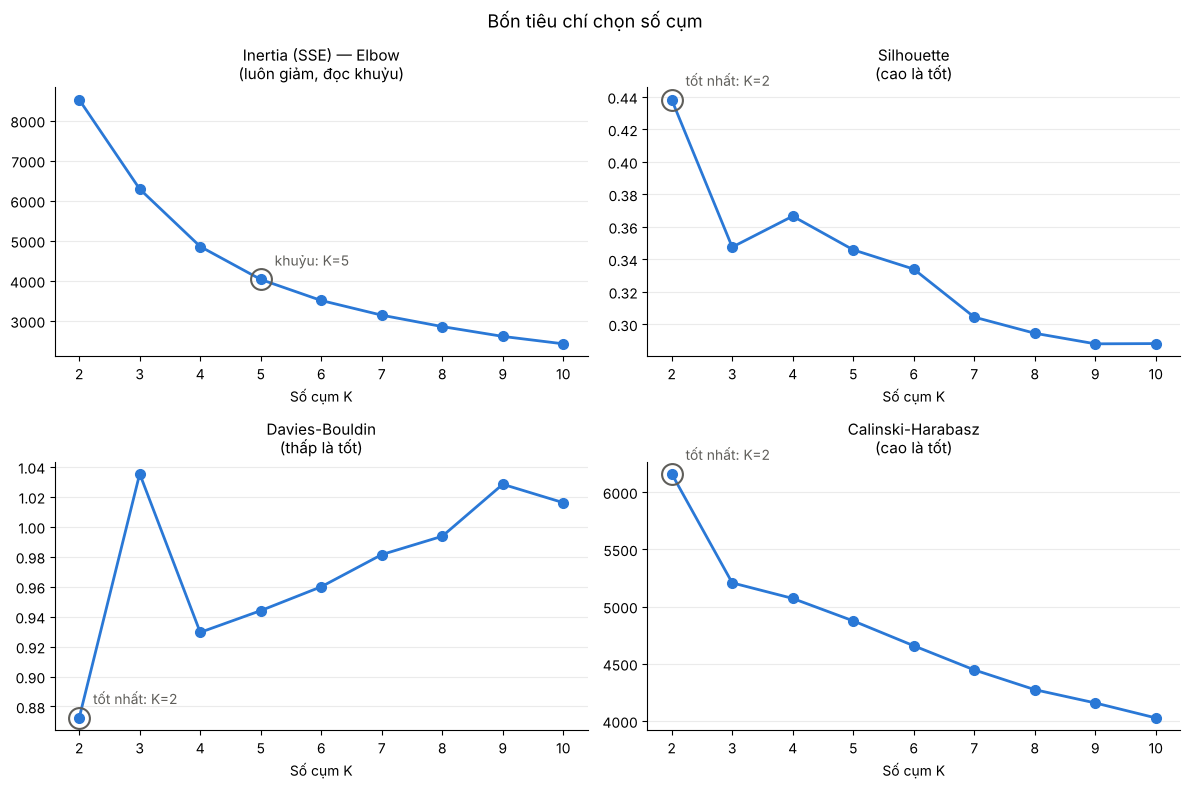

In [6]:
spec = [
    ('inertia',           'Inertia (SSE) — Elbow',  'luôn giảm, đọc khuỷu', 'knee'),
    ('silhouette',        'Silhouette',             'cao là tốt',           'max'),
    ('davies_bouldin',    'Davies-Bouldin',         'thấp là tốt',          'min'),
    ('calinski_harabasz', 'Calinski-Harabasz',      'cao là tốt',           'max'),
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, (col, title, note, rule) in zip(axes.flat, spec):
    ax.plot(scan.index, scan[col], marker='o', color=SERIES, lw=2, ms=7)

    if rule == 'knee':
        best = knee
    else:
        best = scan[col].idxmax() if rule == 'max' else scan[col].idxmin()

    if best is not None:
        ax.plot(best, scan.loc[best, col], 'o', ms=15, mfc='none', mec=INK, mew=1.5)
        label = f'khuỷu: K={best}' if rule == 'knee' else f'tốt nhất: K={best}'
        ax.annotate(label, (best, scan.loc[best, col]), textcoords='offset points',
                    xytext=(10, 10), color=INK, fontsize=10)

    ax.set_title(f'{title}\n({note})', fontsize=11)
    ax.set_xlabel('Số cụm K')
    ax.set_xticks(K_RANGE)
    tidy(ax)

fig.suptitle('Bốn tiêu chí chọn số cụm', fontsize=13)
fig.tight_layout()
plt.show()

### 3.1 Quyết định K

**Cách chọn.** Không có độ đo nào đủ để tự quyết định $K$, nên ta đọc bốn tiêu chí cùng lúc:

1. **Silhouette** — cao là tốt
2. **Davies-Bouldin** — thấp là tốt
3. **Khuỷu** của đường Inertia
4. **Khả năng diễn giải business** — $K$ đó có tạo ra các nhóm khác nhau rõ rệt, đủ để xây
   chiến dịch marketing riêng cho từng nhóm không?

Ba tiêu chí thống kê dùng để khoanh vùng các $K$ **chấp nhận được**. Tiêu chí business dùng
để chọn **trong vùng đó**. Đây là tiêu chí hợp lệ chứ không phải gian lận: chín phân khúc thì
bộ phận marketing không thể làm chín chiến dịch, còn bốn đến năm thì làm được.

**Kết quả:**

| $K$ | Ưu điểm | Nhược điểm |
|---|---|---|
| 2 | Silhouette (0,438), Davies-Bouldin (0,872), Calinski-Harabasz đều tốt nhất | chỉ tách "còn mua / đã bỏ", quá thô để làm marketing |
| **4** | đỉnh phụ của Silhouette (0,367) và đáy phụ của Davies-Bouldin (0,929) | không đứng đầu tuyệt đối ở độ đo nào |
| 5 | KneeLocator chọn làm khuỷu | thua $K = 4$ ở cả Silhouette (0,346) lẫn Davies-Bouldin (0,944) |

**Phân tích:**

- **Vì sao $K = 2$ thắng ở cả ba độ đo.** RFM sau `log1p` là một khối liên tục kéo dài theo
  một trục chính là giá trị khách hàng. Cắt đôi khối dọc trục đó luôn cho tách biệt cao nhất,
  nên các độ đo ưu ái $K$ nhỏ; Calinski-Harabasz còn giảm đều theo $K$. Vì thế $K = 2$ tốt
  nhất về thống kê nhưng không có giá trị phân khúc.
- **Khuỷu không sắc nét.** Inertia giảm lần lượt 26% → 23% → 17% → 13% → 10%, không có điểm
  gãy rõ. Vùng khuỷu là **$K = 4$–5**.
- **Trong vùng khuỷu, $K = 4$ tốt hơn $K = 5$ ở cả hai độ đo** Silhouette và Davies-Bouldin.
- **Bằng chứng độc lập từ dendrogram** (mục 5.1): trong các $K \ge 3$, lát cắt cho 4 cụm có
  dải chiều cao rộng nhất.

**Chọn $K = 4$.**

**Về mức Silhouette 0,37.** Theo thang của Kaufman & Rousseeuw, mức 0,26–0,50 là "cấu trúc yếu".
Điều này phù hợp với bản chất dữ liệu khách hàng: các phân khúc chuyển dần sang nhau chứ
không phải các đảo tách biệt. Phân cụm ở đây là **chia một phổ liên tục thành các vùng có
ý nghĩa hành động**, không phải phát hiện các nhóm có sẵn trong tự nhiên.

In [7]:
K_CHOSEN = 4   # lý do: xem mục 3.1

print(f'K được chọn: {K_CHOSEN}')
print()
print(scan.loc[[K_CHOSEN]].to_string())

K được chọn: 4

    inertia  silhouette  davies_bouldin  calinski_harabasz
K                                                         
4 4,856.384       0.367           0.929          5,070.624


---

## 4. K-Means

### 4.1 Kiểm chứng: cực tiểu địa phương có tồn tại không?

K-Means chỉ đảm bảo hội tụ về **một** cực tiểu, không đảm bảo đó là cực tiểu
**toàn cục**. Nó không có cách nào biết mình đang ở cực tiểu địa phương.

Kiểm chứng bằng thực nghiệm: chạy 30 lần với khởi tạo **ngẫu nhiên** và **chỉ một
lần mỗi lượt** (`init='random', n_init=1`), rồi so với cấu hình chuẩn
(`k-means++`, `n_init=50`).

In [8]:
single_runs = np.array([
    KMeans(n_clusters=K_CHOSEN, init='random', n_init=1, random_state=s).fit(X).inertia_
    for s in range(30)
])

kmeans = KMeans(n_clusters=K_CHOSEN, init='k-means++', n_init=50, random_state=SEED).fit(X)

print('30 lần chạy đơn, khởi tạo ngẫu nhiên:')
print(f'  SSE nhỏ nhất : {single_runs.min():,.2f}')
print(f'  SSE lớn nhất : {single_runs.max():,.2f}')
print(f'  Chênh lệch   : {(single_runs.max() / single_runs.min() - 1) * 100:.3f}%')
# Hai lần chạy coi là cùng một nghiệm nếu SSE sai khác dưới 0,1% (bỏ qua sai số làm tròn)
distinct = np.unique(np.round(single_runs / single_runs.min(), 3))
stuck = (single_runs > single_runs.min() * 1.001).sum()
print(f'  Số nghiệm khác nhau (sai khác > 0,1%): {len(distinct)}')
print(f'  Số lần mắc kẹt ở nghiệm kém hơn: {stuck} / 30')
print()
print(f'k-means++ với n_init=50: SSE = {kmeans.inertia_:,.2f}')

30 lần chạy đơn, khởi tạo ngẫu nhiên:
  SSE nhỏ nhất : 4,856.41
  SSE lớn nhất : 5,396.27
  Chênh lệch   : 11.117%
  Số nghiệm khác nhau (sai khác > 0,1%): 2
  Số lần mắc kẹt ở nghiệm kém hơn: 1 / 30

k-means++ với n_init=50: SSE = 4,856.38


**Cách đọc:**

- Nếu cả 30 lần cho cùng một SSE: dữ liệu chỉ có một "lòng chảo" ổn định ở $K$ này,
  khởi tạo không ảnh hưởng kết quả.
- Nếu có nhiều nghiệm khác nhau: cực tiểu địa phương **có thật** trên dữ liệu này,
  và `n_init=50` là cần thiết chứ không phải thừa.

Trong cả hai trường hợp, cấu hình `k-means++` + `n_init=50` phải cho SSE bằng hoặc
thấp hơn giá trị nhỏ nhất của 30 lần chạy đơn.

**Kết quả:** cực tiểu địa phương **có thật**. Phần lớn các lần chạy đơn hội tụ về cùng một
nghiệm (SSE ≈ 4.856), nhưng có lần mắc kẹt ở nghiệm kém hơn tới **11%** (SSE 5.396).
Nếu chỉ chạy K-Means một lần, ta có thể nhận nghiệm kém này mà không hề hay biết.

Cấu hình `k-means++` + `n_init=50` cho SSE = 4.856,38, bằng nghiệm tốt nhất của 30 lần chạy
đơn. Vì vậy `n_init=50` là **cần thiết**, không phải thừa.

### 4.2 Gán nhãn ổn định

Nhãn cụm do K-Means trả về là **tùy ý** — chạy lại có thể đổi cụm 0 thành cụm 2.
Để diễn giải nhất quán, đánh số lại theo **Monetary trung vị giảm dần**:
cụm 0 luôn là nhóm chi tiêu cao nhất.

In [9]:
def relabel_by_value(labels, ref=rfm['Monetary']):
    # Đánh số lại cụm theo Monetary trung vị giảm dần; nhãn âm (nhiễu DBSCAN) giữ nguyên
    labels = np.asarray(labels)
    valid = labels >= 0
    order = (pd.Series(ref.values[valid]).groupby(labels[valid]).median()
               .sort_values(ascending=False).index)
    mapping = {old: new for new, old in enumerate(order)}
    return np.array([mapping.get(l, l) for l in labels])


labels_km = relabel_by_value(kmeans.labels_)

sizes = pd.Series(labels_km).value_counts().sort_index()
print('Kích thước các cụm K-Means:')
print(pd.DataFrame({'số khách': sizes, '% khách': (sizes / n * 100).round(1)}).to_string())

Kích thước các cụm K-Means:
   số khách  % khách
0      1181   20.200
1      1441   24.700
2      1261   21.600
3      1956   33.500


### 4.3 Ảnh hưởng của outlier tới centroid

Đây là yêu cầu **"handle outliers affecting cluster centroids"** của đề bài.

**Vì sao K-Means nhạy với outlier.** Centroid của K-Means là **trung bình** của cụm,
và trung bình là giá trị tối thiểu hóa tổng **bình phương** khoảng cách. Bình phương
khiến một điểm ở xa bị "phạt" rất nặng — cách 1.000 đơn vị đóng góp $10^6$ — nên
dịch centroid về phía nó làm giảm SSE rất nhiều. Kết quả: centroid bị kéo khỏi
vị trí của khách hàng điển hình.

Online Retail II có các khách bán buôn chi tiêu gấp hàng trăm lần khách lẻ — đúng
loại outlier này.

**Ba cách được so sánh**, cùng $K$:

| Ký hiệu | Phương pháp | Cách xử lý outlier |
|---|---|---|
| **A** | K-Means trên dữ liệu **thô** (chỉ chuẩn hóa) | không xử lý — mốc đối chứng |
| **B** | K-Means trên dữ liệu **`log1p`** + chuẩn hóa | nén đuôi phải trước khi phân cụm — **pipeline chính** |
| **C** | **K-Medoids** trên dữ liệu `log1p` + chuẩn hóa | tâm cụm là **một khách hàng thật**, tối thiểu hóa tổng khoảng cách **không bình phương** |

**Về K-Medoids.** Tâm cụm (medoid) phải là một điểm có thật trong dữ liệu — khách
hàng có tổng khoảng cách tới mọi thành viên khác trong cụm là nhỏ nhất. Vì dùng
khoảng cách **không bình phương**, một điểm ở xa chỉ đóng góp tuyến tính, nên medoid
bền với outlier như trung vị.

Thuật toán PAM gốc có bước hoán đổi tốn $O(K(n-K)^2)$ mỗi vòng, quá chậm với vài
nghìn khách. Ở đây dùng biến thể **lặp xen kẽ** (alternating / Voronoi iteration):
gán mỗi khách về medoid gần nhất, rồi trong mỗi cụm chọn lại medoid tốt nhất, lặp
đến khi không đổi. Cài trực tiếp bằng numpy, không cần thư viện ngoài.

In [10]:
def kmedoids(data, k, n_iter=30, seed=SEED, block=500):
    # Khởi tạo: với mỗi centroid K-Means++, lấy khách hàng thật gần nhất làm medoid ban đầu
    km0 = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=seed).fit(data)
    medoids = np.array([np.argmin(((data - c) ** 2).sum(axis=1)) for c in km0.cluster_centers_])

    for _ in range(n_iter):
        # Bước 1 — gán: mỗi khách về medoid gần nhất
        dist = np.linalg.norm(data[:, None, :] - data[medoids][None, :, :], axis=2)
        labels = dist.argmin(axis=1)

        # Bước 2 — cập nhật: trong mỗi cụm, chọn khách có tổng khoảng cách nhỏ nhất
        new = medoids.copy()
        for c in range(k):
            members = np.where(labels == c)[0]
            if len(members) == 0:
                continue
            sub = data[members]
            cost = np.empty(len(members))
            for s in range(0, len(members), block):   # chia khối để tiết kiệm bộ nhớ
                cost[s:s + block] = np.linalg.norm(
                    sub[s:s + block, None, :] - sub[None, :, :], axis=2).sum(axis=1)
            new[c] = members[cost.argmin()]

        if np.array_equal(new, medoids):
            break
        medoids = new

    dist = np.linalg.norm(data[:, None, :] - data[medoids][None, :, :], axis=2)
    return dist.argmin(axis=1), medoids


def fit_centers(rfm_part, method, k=K_CHOSEN):
    # Chạy một trong ba phương pháp A/B/C trên tập khách cho trước.
    # Trả về: tâm cụm đổi về ĐƠN VỊ GỐC (sắp theo Monetary giảm dần) và nhãn đã đánh số lại tương ứng.
    raw = rfm_part[COLS].to_numpy(dtype=float)

    if method == 'A':
        sc = StandardScaler().fit(raw)
        km = KMeans(n_clusters=k, init='k-means++', n_init=20, random_state=SEED).fit(sc.transform(raw))
        labels, centers = km.labels_, sc.inverse_transform(km.cluster_centers_)
    else:
        lg = np.log1p(raw)
        sc = StandardScaler().fit(lg)
        Z = sc.transform(lg)
        if method == 'B':
            km = KMeans(n_clusters=k, init='k-means++', n_init=20, random_state=SEED).fit(Z)
            labels = km.labels_
            centers = np.expm1(sc.inverse_transform(km.cluster_centers_))   # đổi ngược về đơn vị gốc
        else:  # 'C'
            labels, med = kmedoids(Z, k)
            centers = raw[med]                                              # medoid là khách thật

    order = np.argsort(-centers[:, 2])                 # cụm 0 = Monetary của tâm cao nhất
    remap = np.empty(k, dtype=int)
    remap[order] = np.arange(k)
    labels = remap[labels]

    out = pd.DataFrame(centers[order], columns=COLS)
    out.index.name = 'Cụm'
    out['số khách'] = np.bincount(labels, minlength=k)
    return out, labels


METHODS = {'A': 'K-Means, dữ liệu thô',
           'B': 'K-Means, log1p (chính)',
           'C': 'K-Medoids, log1p'}

t0 = time.time()
full = {m: fit_centers(rfm, m) for m in METHODS}
print(f'Chạy xong ba phương pháp trong {time.time() - t0:.1f} giây')

Chạy xong ba phương pháp trong 1.3 giây


#### So sánh 1 — Kích thước cụm

Dấu hiệu rõ nhất của việc bị outlier chi phối: thuật toán **dành hẳn một hoặc vài
cụm cho một nhúm khách cực đoan**, còn tuyệt đại đa số bị dồn vào một cụm khổng lồ.

In [11]:
sizes_cmp = pd.DataFrame({METHODS[m]: full[m][0]['số khách'] for m in METHODS})
sizes_pct = sizes_cmp / n * 100

print('Số khách mỗi cụm:')
print(sizes_cmp.to_string())
print()
print('Tỉ lệ % — cụm nhỏ nhất và lớn nhất:')
print(pd.DataFrame({'cụm nhỏ nhất (%)': sizes_pct.min(),
                    'cụm lớn nhất (%)': sizes_pct.max()}).to_string())

Số khách mỗi cụm:
     K-Means, dữ liệu thô  K-Means, log1p (chính)  K-Medoids, log1p
Cụm                                                                
0                       4                    1181              1351
1                      36                    1441              1435
2                    3821                    1261              1290
3                    1978                    1956              1763

Tỉ lệ % — cụm nhỏ nhất và lớn nhất:
                        cụm nhỏ nhất (%)  cụm lớn nhất (%)
K-Means, dữ liệu thô               0.069            65.439
K-Means, log1p (chính)            20.226            33.499
K-Medoids, log1p                  22.093            30.194


#### So sánh 2 — Tâm cụm có đại diện cho khách điển hình không?

Tâm cụm đã đổi về đơn vị gốc. Lưu ý cách đổi khác nhau:

- **A:** đổi ngược phép chuẩn hóa → **trung bình cộng** của cụm
- **B:** đổi ngược chuẩn hóa rồi `expm1` → trung bình trong không gian log, tương đương
  **trung bình nhân**, vốn bền với outlier hơn trung bình cộng nhiều
- **C:** medoid là **một khách hàng có thật**, đọc thẳng số liệu của khách đó

Cột cuối so tâm cụm với **trung vị** Monetary của chính các thành viên trong cụm.
Tỉ lệ gần 1 nghĩa là tâm đại diện tốt cho khách điển hình; tỉ lệ lớn hơn nhiều
nghĩa là tâm bị outlier kéo đi.

In [12]:
for m in METHODS:
    centers, labels = full[m]
    member_median = pd.Series(rfm['Monetary'].values).groupby(labels).median()
    show = centers.copy()
    show['M trung vị thành viên'] = member_median.values
    show['tâm / trung vị'] = show['Monetary'] / show['M trung vị thành viên']
    print(f'=== {m}: {METHODS[m]} ===')
    print(show.to_string())
    print()

=== A: K-Means, dữ liệu thô ===
     Recency  Frequency    Monetary  số khách  M trung vị thành viên  tâm / trung vị
Cụm                                                                                 
0      3.750    200.000 415,213.225         4            410,942.565           1.010
1     25.750    102.167  72,315.120        36             54,260.005           1.333
2     67.545      7.193   2,821.307      3821              1,293.710           2.181
3    462.311      2.203     714.217      1978                365.405           1.955

=== B: K-Means, log1p (chính) ===
     Recency  Frequency  Monetary  số khách  M trung vị thành viên  tâm / trung vị
Cụm                                                                               
0     15.799     14.753 5,622.329      1181              4,862.510           1.156
1    177.053      4.557 1,499.135      1441              1,440.400           1.041
2     21.425      2.711   657.769      1261                714.960           0.920
3    335

#### So sánh 3 — Thí nghiệm độ nhạy: bỏ 1% khách chi tiêu cao nhất

Phép thử trực tiếp nhất cho câu hỏi *"outlier ảnh hưởng tới centroid bao nhiêu?"*:
bỏ 1% khách có Monetary cao nhất, **chạy lại toàn bộ** (kể cả bước chuẩn hóa), rồi đo
tâm cụm dịch đi bao nhiêu phần trăm.

Phương pháp bền với outlier thì tâm cụm gần như **không đổi** khi bỏ đi một nhúm nhỏ
khách cực đoan. Phương pháp nhạy thì tâm cụm **nhảy mạnh**, thậm chí cấu trúc cụm thay đổi.

In [13]:
extreme = rfm['Monetary'] >= rfm['Monetary'].quantile(0.99)
print(f'Bỏ {extreme.sum():,} khách (1% Monetary cao nhất, từ {rfm.loc[extreme, "Monetary"].min():,.0f} bảng trở lên)')
print()

reduced = {m: fit_centers(rfm[~extreme], m) for m in METHODS}

shift = pd.DataFrame({
    METHODS[m]: ((reduced[m][0]['Monetary'] - full[m][0]['Monetary']).abs()
                 / full[m][0]['Monetary'] * 100)
    for m in METHODS
})
shift.index.name = 'Cụm'

print('Độ dịch chuyển Monetary của tâm cụm (%):')
print(shift.round(1).to_string())
print()
print('Trung bình độ dịch chuyển (%):')
print(shift.mean().round(1).to_string())

Bỏ 59 khách (1% Monetary cao nhất, từ 26,627 bảng trở lên)



Độ dịch chuyển Monetary của tâm cụm (%):
     K-Means, dữ liệu thô  K-Means, log1p (chính)  K-Medoids, log1p
Cụm                                                                
0                  96.400                  16.900             0.000
1                  92.700                   8.100             0.000
2                  60.900                   3.400             0.000
3                  14.000                   4.100             1.500

Trung bình độ dịch chuyển (%):
K-Means, dữ liệu thô     66.000
K-Means, log1p (chính)    8.100
K-Medoids, log1p          0.400


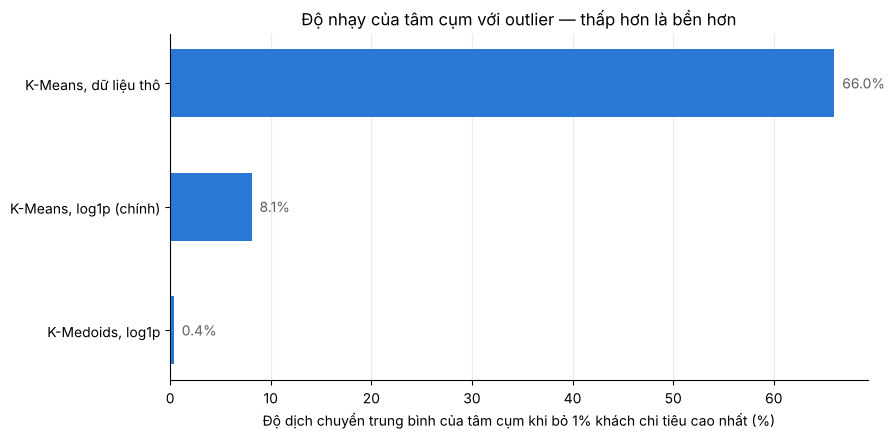

In [14]:
fig, ax = plt.subplots(figsize=(9, 4.5))
vals = shift.mean()
bars = ax.barh(vals.index[::-1], vals.values[::-1], color=SERIES, height=0.55)
for b, v in zip(bars, vals.values[::-1]):
    ax.text(b.get_width(), b.get_y() + b.get_height() / 2, f'  {v:.1f}%',
            va='center', color=INK, fontsize=10)
ax.set_xlabel('Độ dịch chuyển trung bình của tâm cụm khi bỏ 1% khách chi tiêu cao nhất (%)')
ax.set_title('Độ nhạy của tâm cụm với outlier — thấp hơn là bền hơn', fontsize=12)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='x', alpha=0.25)
ax.set_axisbelow(True)
plt.show()

In [15]:
ari_bc = adjusted_rand_score(full['B'][1], full['C'][1])
ari_ab = adjusted_rand_score(full['A'][1], full['B'][1])

print(f'ARI giữa B (K-Means log) và C (K-Medoids log): {ari_bc:.3f}')
print(f'ARI giữa A (K-Means thô) và B (K-Means log)  : {ari_ab:.3f}')

ARI giữa B (K-Means log) và C (K-Medoids log): 0.818
ARI giữa A (K-Means thô) và B (K-Means log)  : 0.175


#### Kết luận mục 4.3

Bỏ 1% khách chi tiêu cao nhất nghĩa là bỏ 59 khách, từ 26.627 bảng trở lên.

**A — K-Means trên dữ liệu thô — thất bại đúng như lý thuyết dự đoán:**

- Dành 2 trong 4 cụm cho **40 khách** (4 + 36), chưa tới 1% khách hàng, trong khi dồn 65,4%
  khách vào một cụm.
- Tâm hai cụm lớn cao gấp **2,2 và 2,0 lần** trung vị của chính các thành viên: trung bình
  cộng bị khách bán buôn kéo khỏi khách điển hình.
- Khi bỏ 59 khách cực đoan, tâm cụm dịch trung bình **66,0%**.
- ARI với B chỉ **0,175**: một cách phân cụm hoàn toàn khác.

**B — K-Means trên dữ liệu `log1p` — trung hoà được outlier:**

- Các cụm cân đối, mỗi cụm 20–33% khách.
- Tâm cụm sát trung vị (tỉ lệ 0,90–1,16).
- Tâm dịch trung bình **8,1%**. Dịch nhiều nhất ở cụm giá trị cao nhất (16,9%), vì đây là
  cụm chứa các khách cực đoan.

**C — K-Medoids — bền nhất:**

- Tâm cụm sát trung vị nhất (tỉ lệ 0,95–0,98).
- Tâm dịch trung bình chỉ **0,4%**: ba trong bốn medoid giữ nguyên. Medoid là một khách thật
  nằm giữa cụm nên không bị đuôi phân phối kéo đi.

**Quyết định.** Dùng **B** làm phân khúc chính cho phần còn lại của notebook:

- ARI(B, C) = **0,818**: hai phương pháp đồng thuận cao, nên kết quả của B không phải sản phẩm
  của outlier.
- K-Means là phương pháp đề bài yêu cầu.
- Mức dịch 8,1% chấp nhận được.

C giữ vai trò kiểm chứng độ bền. A bị loại.

**Hai loại outlier, hai cách xử lý:**

| Loại | Ví dụ | Xử lý |
|---|---|---|
| Outlier **giả** do lỗi dữ liệu | khách 16446 đặt 80.995 sản phẩm rồi huỷ | **sửa** ở bước làm sạch (notebook 01, mục 2.5) |
| Outlier **thật** | khách bán buôn chi hơn 500.000 bảng | **giữ lại**, chỉ giảm ảnh hưởng lên tâm cụm bằng `log1p` |

Khách hàng cực đoan thật **không bị xoá**: họ là khách thật và đóng góp doanh thu lớn nhất.
Ta xử lý **ảnh hưởng** của họ lên tâm cụm, không xử lý **sự tồn tại** của họ. Danh sách cụ
thể các khách này được đưa ra ở mục 6.3 bằng DBSCAN.

---

## 5. Agglomerative Clustering

### 5.1 Dendrogram

Dùng **Ward linkage**: mỗi bước gộp hai cụm làm **tăng phương sai nội cụm ít nhất**.
Đây là linkage gần K-Means nhất về triết lý, nên phù hợp để đối chiếu.

Ưu điểm lớn nhất của phương pháp phân cấp: **không cần biết $K$ trước**. Thuật toán
cho toàn bộ hệ thống cụm ở mọi mức, cắt ngang ở chiều cao nào thì được số cụm tương ứng.

In [16]:
t0 = time.time()
Z = linkage(X, method='ward')
heights = Z[:, 2]
print(f'Dựng cây xong trong {time.time() - t0:.1f} giây')

# Muốn K cụm thì cắt giữa lần gộp thứ (K) và (K-1) tính từ trên xuống
cut = (heights[-K_CHOSEN] + heights[-(K_CHOSEN - 1)]) / 2

# Bước nhảy: dải chiều cao cắt vào thì được đúng K cụm. Dải càng rộng, K đó càng "tự nhiên".
gaps = pd.DataFrame({
    'K': range(2, 11),
    'dải cắt (từ)': [heights[-k]       for k in range(2, 11)],
    'dải cắt (đến)': [heights[-(k - 1)] for k in range(2, 11)],
})
gaps['độ rộng dải'] = gaps['dải cắt (đến)'] - gaps['dải cắt (từ)']
print()
print(gaps.set_index('K').to_string())
print()
print(f'Dải rộng nhất (gợi ý của dendrogram): K = {gaps.loc[gaps["độ rộng dải"].idxmax(), "K"]}')

Dựng cây xong trong 0.9 giây

    dải cắt (từ)  dải cắt (đến)  độ rộng dải
K                                           
2         55.517        132.175       76.658
3         53.338         55.517        2.179
4         42.942         53.338       10.396
5         35.272         42.942        7.670
6         34.200         35.272        1.072
7         24.620         34.200        9.580
8         23.726         24.620        0.894
9         20.254         23.726        3.472
10        19.181         20.254        1.074

Dải rộng nhất (gợi ý của dendrogram): K = 2


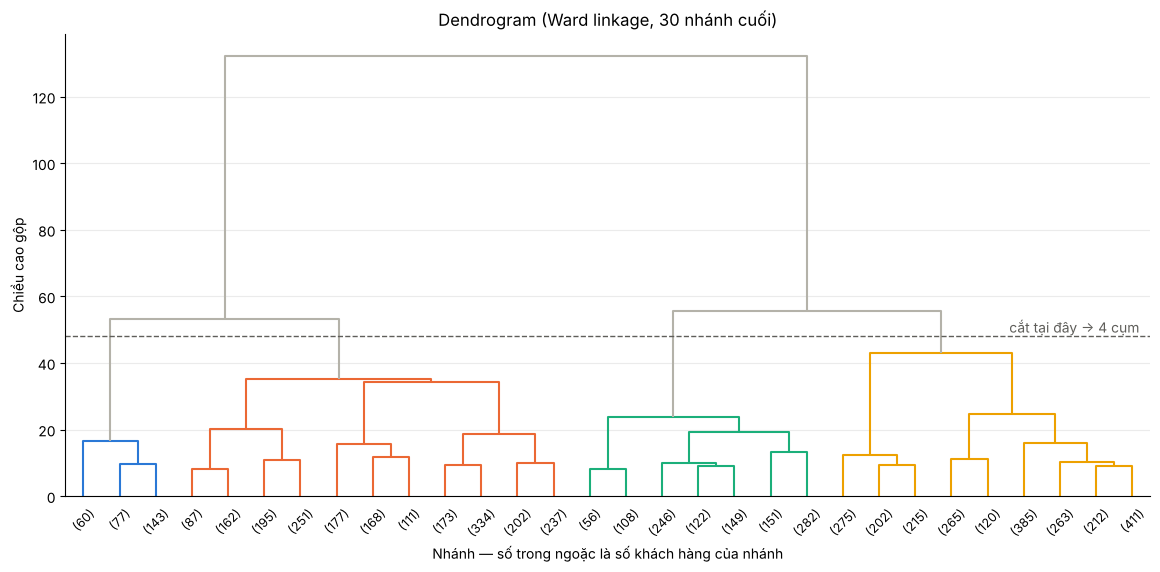

In [17]:
set_link_color_palette(PALETTE[:K_CHOSEN])

fig, ax = plt.subplots(figsize=(14, 6))
dendrogram(Z, truncate_mode='lastp', p=30, color_threshold=cut,
           above_threshold_color='#b4b2a9', ax=ax, leaf_font_size=9)
ax.axhline(cut, ls='--', color=INK, lw=1)
ax.annotate(f'cắt tại đây → {K_CHOSEN} cụm', (0.99, cut), xycoords=('axes fraction', 'data'),
            ha='right', va='bottom', color=INK, fontsize=10)
ax.set_title('Dendrogram (Ward linkage, 30 nhánh cuối)', fontsize=12)
ax.set_xlabel('Nhánh — số trong ngoặc là số khách hàng của nhánh')
ax.set_ylabel('Chiều cao gộp')
tidy(ax)
plt.show()

set_link_color_palette(None)

**Cách đọc dendrogram:** tìm khoảng chiều cao **rộng nhất** mà không có phép gộp
nào — cắt ở đó cho ra số cụm "tự nhiên" nhất. Đây là phiên bản trực quan của Elbow.

Nếu dải rộng nhất ở bảng trên trùng với $K$ đã chọn ở mục 3 thì ta có **hai bằng
chứng độc lập** cho cùng một kết luận — mạnh hơn nhiều so với một.

**Kết quả:** dải rộng nhất ở $K = 2$ (76,7), cùng hướng với các độ đo ở mục 3. Trong các
$K \ge 3$:

| $K$ | Độ rộng dải |
|---|---|
| 3 | 2,2 |
| **4** | **10,4** |
| 5 | 7,7 |
| 7 | 9,6 |

Lát cắt cho 3 cụm gần như không tồn tại (dải chỉ rộng 2,2), còn **$K = 4$ là lát cắt ổn định
nhất** khi cần nhiều hơn hai phân khúc. Đây là bằng chứng độc lập thứ hai ủng hộ $K = 4$.

### 5.2 So sánh bốn loại linkage

| Linkage | Khoảng cách giữa hai cụm | Tính cách |
|---|---|---|
| Ward | mức tăng phương sai khi gộp | gọn, cỡ đều, giống K-Means |
| Complete | **max** các cặp điểm | gọn, nhạy outlier |
| Average | trung bình các cặp | trung hòa |
| Single | **min** các cặp điểm | dài, chuỗi — **chaining effect** |

Single linkage chỉ cần **một** cặp điểm gần nhau là gộp, nên với dữ liệu liên tục
không có khoảng trống rõ ràng, nó thường nuốt gần hết dữ liệu vào một cụm duy nhất.
Cột "cụm lớn nhất" dưới đây sẽ cho thấy điều đó.

In [18]:
rows = []
for link in ['ward', 'complete', 'average', 'single']:
    lab = AgglomerativeClustering(n_clusters=K_CHOSEN, linkage=link).fit_predict(X)
    sz = np.sort(np.bincount(lab))[::-1]
    rows.append({
        'linkage'           : link,
        'silhouette'        : silhouette_score(X, lab),
        'davies_bouldin'    : davies_bouldin_score(X, lab),
        'cụm lớn nhất (%)'  : sz[0] / n * 100,
        'kích thước các cụm': ', '.join(f'{s:,}' for s in sz),
    })

linkage_cmp = pd.DataFrame(rows).set_index('linkage')
print(linkage_cmp.to_string())

          silhouette  davies_bouldin  cụm lớn nhất (%)        kích thước các cụm
linkage                                                                         
ward           0.299           1.028            40.212  2,348, 2,097, 1,114, 280
complete       0.173           1.066            57.013     3,329, 1,919, 520, 71
average        0.396           0.736            74.259       4,336, 1,473, 22, 8
single         0.132           0.560            99.949            5,836, 1, 1, 1


**Kết quả — bài học quan trọng nhất của phần này:**

- **Single linkage** bị chaining hoàn toàn: dồn 99,95% khách vào một cụm, ba cụm còn lại mỗi
  cụm đúng **1 khách**.
- **Average linkage** cho Silhouette **cao nhất** trong bốn loại (0,396, cao hơn cả K-Means)
  và Davies-Bouldin thấp. Nhưng nó dồn 74% khách vào một cụm và tạo ra hai cụm chỉ có
  **22 và 8 khách**.
- **Complete linkage** cũng mất cân đối (một cụm 57%, một cụm 71 khách) và Silhouette thấp.
- **Ward** là linkage duy nhất cho các cụm có kích thước hợp lý.

Bài học: **không bao giờ chọn mô hình chỉ dựa vào độ đo nội tại.** Tách riêng vài khách dị
biệt thành cụm nhỏ làm Silhouette trông đẹp, nhưng kết quả vô dụng cho phân khúc. Luôn phải
xem kèm **kích thước cụm**.

### 5.3 Đối chiếu Agglomerative với K-Means

**Adjusted Rand Index (ARI)** đo mức hai cách phân cụm đồng thuận với nhau, đã hiệu
chỉnh cho sự trùng hợp ngẫu nhiên:

| ARI | Ý nghĩa |
|---|---|
| 1 | hai cách phân cụm giống hệt nhau |
| khoảng 0 | không hơn gì gán ngẫu nhiên |

Hai thuật toán có giả định khác nhau. Nếu chúng cho ra cấu trúc giống nhau thì
cấu trúc đó **có thật trong dữ liệu**, không phải sản phẩm của một thuật toán cụ thể.

In [19]:
labels_ag = relabel_by_value(
    AgglomerativeClustering(n_clusters=K_CHOSEN, linkage='ward').fit_predict(X)
)

ari = adjusted_rand_score(labels_km, labels_ag)
print(f'ARI giữa K-Means và Agglomerative (Ward): {ari:.3f}')
print()
print('Bảng chéo (hàng: K-Means, cột: Agglomerative):')
print(pd.crosstab(pd.Series(labels_km, name='K-Means'),
                  pd.Series(labels_ag, name='Agglo')).to_string())

ARI giữa K-Means và Agglomerative (Ward): 0.355

Bảng chéo (hàng: K-Means, cột: Agglomerative):
Agglo      0    1    2     3
K-Means                     
0        280  901    0     0
1          0  645  125   671
2          0  551  707     3
3          0    0  282  1674


**Kết quả:** ARI = **0,355**, mức đồng thuận vừa phải. Bảng chéo cho thấy hai thuật toán
**cắt ở những chỗ khác nhau** trên cùng một trục giá trị:

- Ward tách riêng một nhóm **280 khách giá trị cao nhất** từ cụm VIP của K-Means, rồi gộp
  phần còn lại của nhóm VIP với một phần khách "nguy cơ" và "tiềm năng".
- Bất đồng chỉ xảy ra giữa các phân khúc **giáp ranh nhau** trong không gian RFM. Không có cụm
  Ward nào trộn hai thái cực: khách VIP và khách đã rời luôn nằm ở hai cụm khác nhau.

Nghĩa là: **thứ tự các tầng giá trị là có thật** (cả hai thuật toán đều thấy), nhưng **vị trí
ranh giới** giữa các tầng mang tính quy ước. Đây là hệ quả trực tiếp của cấu trúc yếu đã thấy
ở mục 3: dữ liệu liên tục không có khe hở tự nhiên để mọi thuật toán cùng cắt vào.

**Vì sao chọn K-Means làm phân khúc chính:** K-Means tốt hơn Ward ở cả hai độ đo (Silhouette
0,367 so với 0,299; Davies-Bouldin 0,929 so với 1,028). Ward gộp theo kiểu tham lam: một
phép gộp đã thực hiện thì không sửa lại được. K-Means thì tối ưu trực tiếp tổng phương sai
nội cụm trên toàn bộ dữ liệu.

---

## 6. DBSCAN

### 6.1 Chọn tham số bằng k-distance graph

**MinPts** chọn trước theo quy tắc thông dụng $MinPts = 2d$. Với $d = 3$ chiều
(R, F, M) thì $MinPts = 6$.

**Eps** tìm bằng k-distance graph với $k = MinPts - 1 = 5$. Trừ 1 vì $MinPts$ đếm
**cả chính điểm đó**, còn $k$ đếm **láng giềng** — tức các điểm khác. Một core point
cần 6 điểm trong vùng lân cận nghĩa là chính nó cộng 5 láng giềng.

Khi gọi `NearestNeighbors.kneighbors`, sklearn trả về **cả chính điểm đó** ở khoảng
cách 0, nên phải hỏi `n_neighbors = MinPts = 6` rồi lấy cột cuối.

In [20]:
MIN_PTS = 2 * d
k = MIN_PTS - 1

nn = NearestNeighbors(n_neighbors=MIN_PTS).fit(X)
kth_dist = nn.kneighbors(X)[0][:, -1]          # khoảng cách tới láng giềng thứ k
kdist = np.sort(kth_dist)[::-1]                 # sắp giảm dần

kn = KneeLocator(np.arange(len(kdist)), kdist, curve='convex', direction='decreasing')
if kn.knee is not None:
    EPS = float(kdist[kn.knee])
    eps_note = f'điểm khuỷu tại vị trí {kn.knee:,}'
else:
    EPS = float(np.quantile(kth_dist, 0.95))
    eps_note = 'KHÔNG tìm thấy khuỷu rõ — dùng phân vị 95% thay thế'

print(f'MinPts = {MIN_PTS}, k = {k}')
print(f'Eps    = {EPS:.4f}  ({eps_note})')

MinPts = 6, k = 5
Eps    = 0.4364  (điểm khuỷu tại vị trí 150)


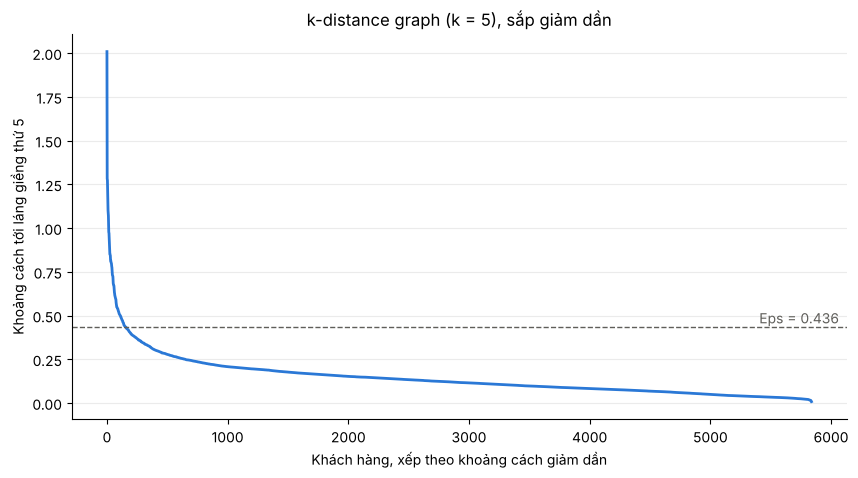

In [21]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(np.arange(len(kdist)), kdist, color=SERIES, lw=2)
ax.axhline(EPS, ls='--', color=INK, lw=1)
ax.annotate(f'Eps = {EPS:.3f}', (0.99, EPS), xycoords=('axes fraction', 'data'),
            ha='right', va='bottom', color=INK, fontsize=10)
ax.set_title(f'k-distance graph (k = {k}), sắp giảm dần', fontsize=12)
ax.set_xlabel('Khách hàng, xếp theo khoảng cách giảm dần')
ax.set_ylabel(f'Khoảng cách tới láng giềng thứ {k}')
tidy(ax)
plt.show()

**Cách đọc:** bên trái khuỷu là các khách **thưa** — khoảng cách tới láng giềng lớn,
là ứng viên nhiễu. Bên phải khuỷu là các khách nằm trong vùng **đông**.

Nếu đường cong **không có khuỷu rõ** mà giảm mượt, đó là dấu hiệu dữ liệu **không có
các vùng mật độ tách biệt** — một phát hiện có giá trị, xem mục 6.3.

In [22]:
db = DBSCAN(eps=EPS, min_samples=MIN_PTS).fit(X)
labels_db = relabel_by_value(db.labels_)

n_clusters_db = len(set(labels_db)) - (1 if -1 in labels_db else 0)
noise = labels_db == -1

print(f'Số cụm      : {n_clusters_db}')
print(f'Điểm nhiễu  : {noise.sum():,} khách ({noise.mean():.1%})')
print()
print('Kích thước:')
print(pd.Series(labels_db).value_counts().sort_index().rename({-1: 'nhiễu (-1)'}).to_string())

if n_clusters_db >= 2:
    print(f'\nSilhouette (bỏ điểm nhiễu): {silhouette_score(X[~noise], labels_db[~noise]):.3f}')

Số cụm      : 2
Điểm nhiễu  : 83 khách (1.4%)

Kích thước:
nhiễu (-1)      83
0             4154
1             1602



Silhouette (bỏ điểm nhiễu): 0.278


### 6.2 Độ nhạy tham số

DBSCAN dùng **một** bộ $(Eps, MinPts)$ cho toàn bộ dữ liệu, nên rất nhạy với $Eps$:
quá nhỏ thì hầu hết điểm thành nhiễu, quá lớn thì mọi thứ gộp thành một cụm.

In [23]:
rows = []
for mult in [0.5, 0.75, 1.0, 1.25, 1.5, 2.0]:
    lab = DBSCAN(eps=EPS * mult, min_samples=MIN_PTS).fit_predict(X)
    rows.append({
        'Eps'        : EPS * mult,
        'hệ số'      : f'{mult}×',
        'số cụm'     : len(set(lab)) - (1 if -1 in lab else 0),
        '% nhiễu'    : (lab == -1).mean() * 100,
    })
print(pd.DataFrame(rows).to_string(index=False))

  Eps hệ số  số cụm  % nhiễu
0.218  0.5×      11    9.351
0.327 0.75×       5    3.271
0.436  1.0×       2    1.421
0.545 1.25×       1    0.873
0.655  1.5×       1    0.565
0.873  2.0×       1    0.154


### 6.3 Khách hàng dị biệt

Điểm nhiễu của DBSCAN là khách hàng **không thuộc vùng đông nào** — thường là khách
bán buôn có hành vi khác hẳn số đông. K-Means buộc phải nhét họ vào một cụm và làm
lệch centroid; DBSCAN tách riêng họ ra.

Danh sách này có giá trị business trực tiếp: đây là nhóm cần chăm sóc riêng.

In [24]:
outliers = rfm.loc[noise, COLS].sort_values('Monetary', ascending=False)

print(f'{len(outliers):,} khách dị biệt, chiếm {outliers["Monetary"].sum() / rfm["Monetary"].sum():.1%} tổng doanh thu')
print()
print('10 khách dị biệt có Monetary cao nhất:')
print(outliers.head(10).to_string())

83 khách dị biệt, chiếm 28.2% tổng doanh thu

10 khách dị biệt có Monetary cao nhất:
             Recency  Frequency    Monetary
Customer ID                                
18102              1        145 579,128.640
14646              2        143 523,361.340
14156             10        143 298,523.790
14911              2        369 259,839.130
17450              9         49 233,675.910
13694              4        141 191,233.070
17511              3         59 169,626.870
12415             25         23 143,275.720
16684              5         53 141,955.550
15061              4        126 125,720.730


### 6.4 Các cụm DBSCAN thực chất là gì?

DBSCAN không cần biết $K$ trước, nên số cụm nó tìm ra là thông tin về **mật độ** của dữ
liệu. Cần xem mỗi cụm DBSCAN chứa những khách nào, và các khách dị biệt rơi vào phân
khúc K-Means nào.

In [25]:
print('Frequency theo cụm DBSCAN:')
print(rfm.groupby(labels_db)['Frequency'].describe()[['count', 'min', '50%', 'max']]
      .rename(index={-1: 'nhiễu (-1)'}).to_string())
print()
print('Khách dị biệt (nhiễu DBSCAN) nằm ở cụm K-Means nào:')
print(pd.Series(labels_km[noise]).value_counts().sort_index()
      .rename_axis('Cụm K-Means').to_string())

Frequency theo cụm DBSCAN:
               count   min    50%     max
nhiễu (-1)    83.000 1.000 20.000 369.000
0          4,154.000 2.000  4.000  81.000
1          1,602.000 1.000  1.000   1.000

Khách dị biệt (nhiễu DBSCAN) nằm ở cụm K-Means nào:
Cụm K-Means
0    52
1    12
2     9
3    10


#### Kết luận mục 6

**1. DBSCAN không tìm thấy 4 vùng mật độ tách biệt.** Với Eps chọn từ khuỷu (0,436), DBSCAN
cho 2 cụm. Khi thay đổi Eps, số cụm nhảy từ 11 (Eps × 0,5) xuống 5, 2 rồi 1, không có mức
nào ổn định. Dữ liệu là **một khối liên tục**, đúng như Silhouette ở mục 3 đã gợi ý.

**2. Hai cụm DBSCAN là sản phẩm của dữ liệu rời rạc, không phải phân khúc hành vi.** Cụm
1.602 khách gồm **đúng những khách chỉ mua 1 lần**, cụm còn lại gồm khách mua từ 2 lần trở
lên. Frequency là số nguyên nên sau `log1p` có một khe hở giữa $\ln 2$ và $\ln 3$, và DBSCAN
cắt đúng vào khe hở này.

**3. Giá trị thật của DBSCAN là tìm khách dị biệt.** 83 khách nhiễu chỉ chiếm 1,4% số khách
nhưng đóng góp **28,2% doanh thu**. 52 người trong số đó thuộc phân khúc VIP của K-Means. Đây
là danh sách khách bán buôn cần chăm sóc riêng, ngoài các chiến dịch theo phân khúc.

**Vai trò của mỗi thuật toán:** K-Means đúng để *chia* khối liên tục thành các phân khúc vì
nó tối ưu SSE chứ không đòi hỏi khe hở giữa các cụm. DBSCAN đúng để *tìm khách dị biệt*.

---

## 7. Đánh giá chi tiết cụm K-Means

### 7.1 Silhouette plot

Con số Silhouette trung bình che mất thông tin. Biểu đồ dưới đây cho thấy từng khách:
mỗi dải là một cụm, các thanh ngang là $s(i)$ của từng khách sắp giảm dần.

Đọc ba điều: cụm nào **lỏng** (nhiều thanh ngắn), cụm nào có **thanh âm** (khách bị
gán sai cụm), và các cụm có **độ dày đều** nhau không.

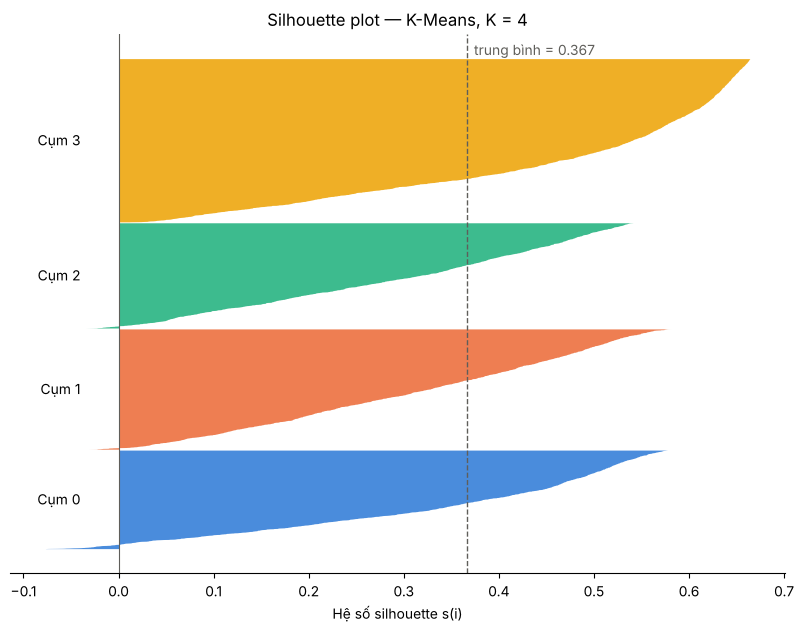

Khách có s(i) < 0 (có thể bị gán sai cụm): 96 (1.6%)

     s(i) trung bình  số khách s(i) < 0
Cụm                                    
0              0.341                 52
1              0.312                 19
2              0.294                 25
3              0.469                  0


In [26]:
sil = silhouette_samples(X, labels_km)
sil_avg = sil.mean()

fig, ax = plt.subplots(figsize=(10, 7))
y_low = 10
for c in range(K_CHOSEN):
    vals = np.sort(sil[labels_km == c])
    y_up = y_low + len(vals)
    ax.fill_betweenx(np.arange(y_low, y_up), 0, vals, color=PALETTE[c], alpha=0.85, lw=0)
    ax.text(-0.04, (y_low + y_up) / 2, f'Cụm {c}', ha='right', va='center', fontsize=10)
    y_low = y_up + 10

ax.axvline(sil_avg, ls='--', color=INK, lw=1)
ax.annotate(f'trung bình = {sil_avg:.3f}', (sil_avg, 1.0), xycoords=('data', 'axes fraction'),
            xytext=(5, -15), textcoords='offset points', color=INK, fontsize=10)
ax.axvline(0, color=INK, lw=0.8)
ax.set_title(f'Silhouette plot — K-Means, K = {K_CHOSEN}', fontsize=12)
ax.set_xlabel('Hệ số silhouette s(i)')
ax.set_yticks([])
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
plt.show()

neg = (sil < 0).sum()
print(f'Khách có s(i) < 0 (có thể bị gán sai cụm): {neg:,} ({neg / n:.1%})')
print()
print(pd.DataFrame({'s(i) trung bình': pd.Series(sil).groupby(labels_km).mean(),
                    'số khách s(i) < 0': pd.Series(sil < 0).groupby(labels_km).sum()})
      .rename_axis('Cụm').round(3).to_string())

**Kết quả:**

- Chỉ **96 khách (1,6%)** có $s(i) < 0$: rất ít khách bị gán nhầm cụm.
- Cụm 3 (khách đã rời) tách biệt rõ nhất: $s(i)$ trung bình 0,469 và **không có** khách nào âm.
- Ba cụm còn lại có $s(i)$ trung bình 0,29–0,34. Đây là các cụm nằm cạnh nhau trên trục giá
  trị nên ranh giới mờ hơn.
- Bốn dải có độ dày tương đương nhau (20–34% khách): không có cụm nào bị nuốt hay bị bỏ rơi.

---

## 8. Đặc tả và đặt tên phân khúc

### 8.1 Bảng profile

Dùng **RFM thô** và **trung vị** thay vì trung bình — trung vị không bị khách bán
buôn kéo lệch, nên đại diện đúng hơn cho khách điển hình của mỗi cụm.

Nhắc lại hướng đọc: **Recency thấp là tốt** (vừa mua gần đây), còn Frequency và
Monetary thì cao là tốt.

In [27]:
seg = rfm[COLS].assign(Cluster=labels_km)

profile = seg.groupby('Cluster').agg(
    so_khach  =('Recency',   'size'),
    R_median  =('Recency',   'median'),
    F_median  =('Frequency', 'median'),
    M_median  =('Monetary',  'median'),
    M_mean    =('Monetary',  'mean'),
    doanh_thu =('Monetary',  'sum'),
)
profile['% khách']     = profile['so_khach']  / profile['so_khach'].sum()  * 100
profile['% doanh thu'] = profile['doanh_thu'] / profile['doanh_thu'].sum() * 100

print(profile.to_string())

         so_khach  R_median  F_median  M_median     M_mean      doanh_thu  % khách  % doanh thu
Cluster                                                                                        
0            1181    17.000    13.000 4,862.510 10,263.973 12,121,751.970   20.226       73.647
1            1441   185.000     4.000 1,440.400  1,852.372  2,669,268.350   24.679       16.217
2            1261    24.000     3.000   714.960    837.624  1,056,244.110   21.596        6.417
3            1956   402.000     1.000   268.685    312.871    611,976.410   33.499        3.718


### 8.2 Gợi ý tên phân khúc

Mỗi chiều của từng cụm được xếp vào một trong ba mức, bằng cách so trung vị của cụm
với **tam phân vị** (phân vị 33% và 67%) của toàn bộ khách hàng:

| Mức | Điều kiện |
|---|---|
| thấp | $\le$ phân vị 33% |
| vừa | giữa hai phân vị |
| cao | $\ge$ phân vị 67% |

Dùng ba mức thay vì chỉ "trên/dưới trung vị" vì hai mức quá thô: với 4 cụm trở lên,
nhiều cụm sẽ rơi vào cùng một ô và bị đặt trùng tên.

Quy tắc áp dụng theo thứ tự, gặp dòng nào khớp trước thì dùng dòng đó.
**Nhắc lại: Recency thấp là tốt.**

| # | Recency | Frequency | Monetary | Gợi ý |
|---|---|---|---|---|
| 1 | thấp | cao | cao | Khách VIP |
| 2 | thấp | thấp | — | Khách mới |
| 3 | thấp | cao | — | Khách trung thành |
| 4 | thấp | vừa | — | Khách tiềm năng |
| 5 | cao | cao hoặc vừa | cao hoặc vừa | Khách giá trị đã rời bỏ |
| 6 | cao | — | — | Khách đã rời |
| 7 | vừa | cao hoặc vừa | cao hoặc vừa | Khách có nguy cơ rời bỏ |
| 8 | vừa | thấp | — | Khách đang nguội dần |
| 9 | còn lại | | | Khách trung bình |

Hai điểm thiết kế:

- **Mua gần đây chưa đủ để gọi là "trung thành".** Một khách vừa mua tuần trước nhưng mới
  mua 3 đơn khác hẳn khách mua 13 đơn. Dòng 3 và dòng 4 tách hai trường hợp này.
- **Recency "vừa" kèm F, M khá là dấu hiệu nguy hiểm nhất** (dòng 7): khách từng mua tốt
  nhưng đang im lặng. Đây là nhóm đáng đầu tư giữ chân nhất, không được gộp vào "trung bình".

Đây chỉ là **gợi ý khởi đầu** dựa trên luật. Tên cuối cùng phải được kiểm tra lại bằng
bảng profile và snake plot (mục 8.4). Nếu hai cụm trùng tên, notebook tự gắn thêm số cụm
và in cảnh báo.

In [28]:
q33 = rfm[COLS].quantile(0.33)
q67 = rfm[COLS].quantile(0.67)

def level(value, col):
    if value <= q33[col]:
        return 'thấp'
    if value >= q67[col]:
        return 'cao'
    return 'vừa'


def suggest_name(row):
    r = level(row['R_median'], 'Recency')
    f = level(row['F_median'], 'Frequency')
    m = level(row['M_median'], 'Monetary')
    if r == 'thấp' and f == 'cao' and m == 'cao':
        return 'Khách VIP'
    if r == 'thấp' and f == 'thấp':
        return 'Khách mới'
    if r == 'thấp' and f == 'cao':
        return 'Khách trung thành'
    if r == 'thấp':
        return 'Khách tiềm năng'
    if r == 'cao' and f != 'thấp' and m != 'thấp':
        return 'Khách giá trị đã rời bỏ'
    if r == 'cao':
        return 'Khách đã rời'
    if r == 'vừa' and f != 'thấp' and m != 'thấp':
        return 'Khách có nguy cơ rời bỏ'
    if r == 'vừa' and f == 'thấp':
        return 'Khách đang nguội dần'
    return 'Khách trung bình'


profile['R'] = [level(v, 'Recency')   for v in profile['R_median']]
profile['F'] = [level(v, 'Frequency') for v in profile['F_median']]
profile['M'] = [level(v, 'Monetary')  for v in profile['M_median']]
profile['Gợi ý tên'] = profile.apply(suggest_name, axis=1)

# Bắt buộc tên không trùng: cụm trùng tên được gắn thêm số cụm
dup = profile['Gợi ý tên'].duplicated(keep=False)
if dup.any():
    profile.loc[dup, 'Gợi ý tên'] = [f'{name} (cụm {c})'
                                     for c, name in profile.loc[dup, 'Gợi ý tên'].items()]
    print('CẢNH BÁO: có cụm trùng tên gợi ý — đã gắn số cụm để phân biệt.')
    print('          Hãy đọc bảng dưới và đặt tên tay ở cell tiếp theo.\n')

print('Tam phân vị toàn bộ khách hàng (mốc so sánh):')
print(pd.DataFrame({'phân vị 33%': q33, 'phân vị 67%': q67}).to_string())
print()
print(profile[['so_khach', '% khách', 'R_median', 'F_median', 'M_median',
               'R', 'F', 'M', '% doanh thu', 'Gợi ý tên']].to_string())

Tam phân vị toàn bộ khách hàng (mốc so sánh):
           phân vị 33%  phân vị 67%
Recency         41.000      267.000
Frequency        2.000        5.000
Monetary       450.219    1,569.136

         so_khach  % khách  R_median  F_median  M_median     R     F     M  % doanh thu                Gợi ý tên
Cluster                                                                                                         
0            1181   20.226    17.000    13.000 4,862.510  thấp   cao   cao       73.647                Khách VIP
1            1441   24.679   185.000     4.000 1,440.400   vừa   vừa   vừa       16.217  Khách có nguy cơ rời bỏ
2            1261   21.596    24.000     3.000   714.960  thấp   vừa   vừa        6.417          Khách tiềm năng
3            1956   33.499   402.000     1.000   268.685   cao  thấp  thấp        3.718             Khách đã rời


In [29]:
# Tên phân khúc lấy từ gợi ý ở trên, đã đối chiếu với profile và snake plot.
# Muốn sửa tay thì ghi đè, ví dụ:
# SEGMENT_NAMES = {0: 'Khách VIP', 1: 'Khách có nguy cơ rời bỏ', 2: 'Khách mới', 3: 'Khách đã rời'}
SEGMENT_NAMES = profile['Gợi ý tên'].to_dict()

assert len(set(SEGMENT_NAMES.values())) == len(SEGMENT_NAMES), 'Có hai phân khúc trùng tên'
print(SEGMENT_NAMES)

{0: 'Khách VIP', 1: 'Khách có nguy cơ rời bỏ', 2: 'Khách tiềm năng', 3: 'Khách đã rời'}


### 8.3 Kiểm chứng: "tiềm năng" hay "mới"?

RFM không phân biệt được hai kiểu khách cùng có Recency thấp và Frequency thấp:

- **khách mới**: mới bắt đầu mua, chưa đủ thời gian để mua nhiều lần
- **khách mua thưa**: đã mua từ lâu nhưng ít khi mua

Để tách hai trường hợp, tính thêm **thâm niên** (tenure) của mỗi khách: số ngày kể từ lần
mua **đầu tiên** tới ngày tham chiếu. Đây là chỉ số ngoài RFM, chỉ dùng để diễn giải chứ
không đưa vào thuật toán.

In [30]:
tx = pd.read_parquet(DATA / 'retail_clean.parquet', columns=['Customer ID', 'InvoiceDate'])
snapshot = tx['InvoiceDate'].max().normalize() + pd.Timedelta(days=1)
first_buy = tx.groupby('Customer ID')['InvoiceDate'].min().dt.normalize()
tenure = (snapshot - first_buy).dt.days.reindex(rfm.index)

ten = pd.DataFrame({'Cluster': labels_km, 'Tenure': tenure.values})
tenure_tbl = ten.groupby('Cluster')['Tenure'].median().to_frame('Tenure trung vị (ngày)')
tenure_tbl['% mua lần đầu ≤ 90 ngày']  = (ten['Tenure'] <= 90).groupby(ten['Cluster']).mean() * 100
tenure_tbl['% mua lần đầu ≤ 180 ngày'] = (ten['Tenure'] <= 180).groupby(ten['Cluster']).mean() * 100
tenure_tbl.insert(0, 'Phân khúc', tenure_tbl.index.map(SEGMENT_NAMES))

print(f'Tenure trung vị của toàn bộ khách: {tenure.median():.0f} ngày')
print()
print(tenure_tbl.round(1).to_string())

Tenure trung vị của toàn bộ khách: 530 ngày

                       Phân khúc  Tenure trung vị (ngày)  % mua lần đầu ≤ 90 ngày  % mua lần đầu ≤ 180 ngày
Cluster                                                                                                    
0                      Khách VIP                 678.000                    1.300                     2.900
1        Khách có nguy cơ rời bỏ                 619.000                    0.300                     2.100
2                Khách tiềm năng                 220.000                   35.400                    46.200
3                   Khách đã rời                 440.000                    6.400                    12.800


**Kết quả:** cụm 2 có thâm niên trung vị **220 ngày**, chưa bằng một nửa mức chung (530 ngày).
**46%** khách của cụm mua lần đầu trong 6 tháng gần nhất, trong khi ở ba cụm còn lại tỉ lệ
này chỉ 2–13%.

Cụm 2 vì vậy là **hỗn hợp**: gần một nửa là khách mới, phần còn lại là khách cũ mua thưa.
Tên **"Khách tiềm năng"** đúng cho cả hai nhóm: cả hai đều vừa mua gần đây và chưa mua nhiều,
nên mục tiêu chung là khuyến khích mua lặp lại.

### 8.4 Snake plot

Biểu đồ đường so sánh **giá trị chuẩn hóa trung bình** của từng cụm trên ba chiều.
Dùng dữ liệu chuẩn hóa ở đây vì cần đặt ba chiều lên cùng một thang để so sánh hình dạng.

Đường nằm **trên 0** nghĩa là cụm đó cao hơn trung bình chung ở chiều tương ứng.
Lưu ý với Recency: **trên 0 là xấu** (lâu rồi chưa mua).

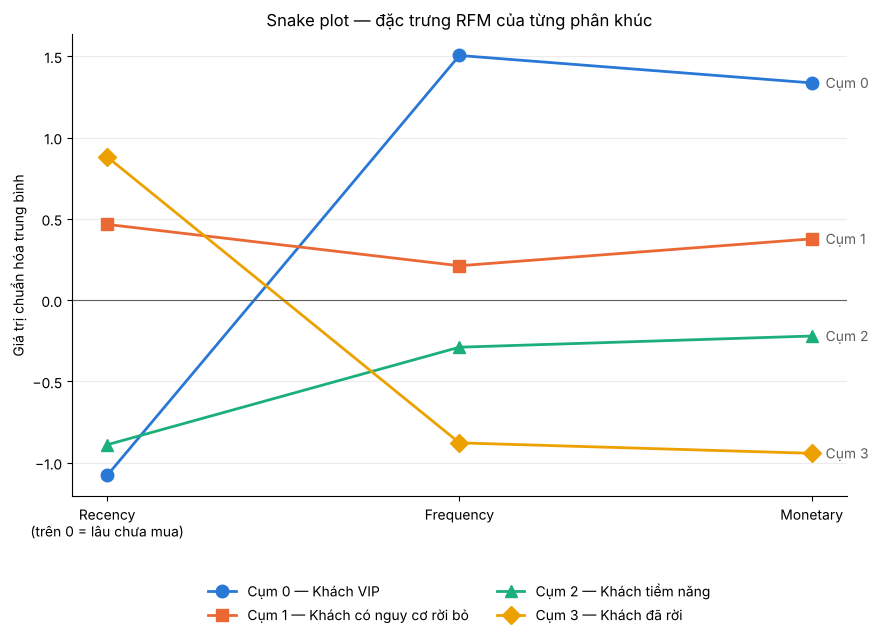

In [31]:
snake = X_df.assign(Cluster=labels_km).groupby('Cluster').mean()
snake.columns = ['Recency', 'Frequency', 'Monetary']

fig, ax = plt.subplots(figsize=(10, 6))
x = np.arange(3)
for c in snake.index:
    ax.plot(x, snake.loc[c], marker=MARKERS[c], ms=9, lw=2, color=PALETTE[c],
            label=f'Cụm {c} — {SEGMENT_NAMES[c]}')
    if K_CHOSEN <= 4:   # nhãn trực tiếp ở đầu đường khi ít chuỗi
        ax.annotate(f'Cụm {c}', (x[-1], snake.loc[c].iloc[-1]), textcoords='offset points',
                    xytext=(10, 0), va='center', color=INK, fontsize=10)

ax.axhline(0, color=INK, lw=0.8)
ax.set_xticks(x)
ax.set_xticklabels(['Recency\n(trên 0 = lâu chưa mua)', 'Frequency', 'Monetary'])
ax.set_ylabel('Giá trị chuẩn hóa trung bình')
ax.set_title('Snake plot — đặc trưng RFM của từng phân khúc', fontsize=12)
ax.legend(frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.16), ncol=2)
tidy(ax)
plt.show()

### 8.5 Phân khúc trên không gian RFM

Hai biểu đồ tán xạ trên **trục log** của dữ liệu thô — trục có đơn vị thật (ngày,
số hóa đơn, bảng Anh) nên đọc được trực tiếp. Mỗi cụm vừa có màu riêng vừa có hình
dạng điểm riêng, để phân biệt được cả khi in đen trắng.

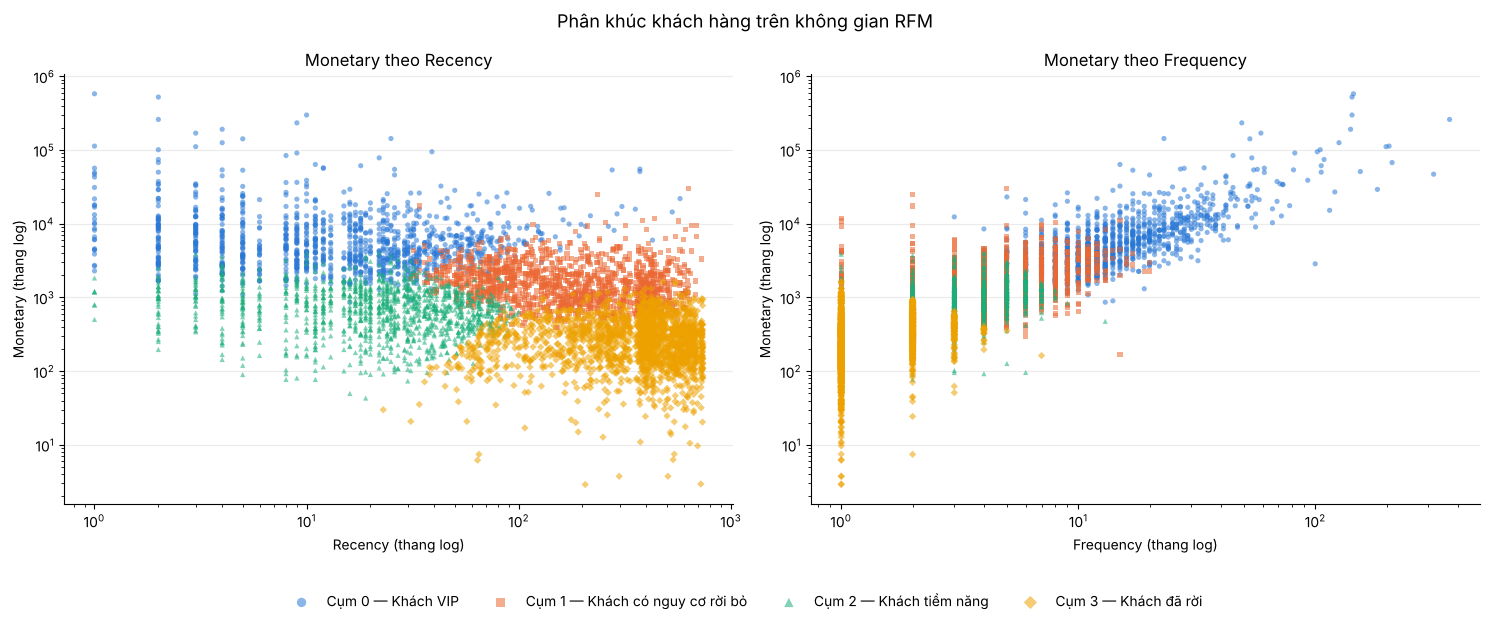

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
pairs = [('Recency', 'Monetary'), ('Frequency', 'Monetary')]

for ax, (xc, yc) in zip(axes, pairs):
    for c in range(K_CHOSEN):
        m = labels_km == c
        ax.scatter(rfm.loc[m, xc], rfm.loc[m, yc], s=14, alpha=0.55,
                   color=PALETTE[c], marker=MARKERS[c], edgecolors='none',
                   label=f'Cụm {c} — {SEGMENT_NAMES[c]}')
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel(f'{xc} (thang log)')
    ax.set_ylabel(f'{yc} (thang log)')
    ax.set_title(f'{yc} theo {xc}', fontsize=12)
    tidy(ax)

handles, labs = axes[0].get_legend_handles_labels()
fig.legend(handles, labs, loc='lower center', ncol=min(K_CHOSEN, 4), frameon=False,
           markerscale=1.8, bbox_to_anchor=(0.5, -0.04))
fig.suptitle('Phân khúc khách hàng trên không gian RFM', fontsize=13)
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

### 8.6 Kết luận phân khúc

| Cụm | Phân khúc | Khách | Doanh thu | R / F / M (trung vị) | Hành động gợi ý |
|---|---|---|---|---|---|
| 0 | **Khách VIP** | 20,2% | **73,6%** | 17 ngày / 13 đơn / 4.863 £ | chăm sóc riêng, ưu đãi khách thân thiết; không cần giảm giá đại trà |
| 1 | **Khách có nguy cơ rời bỏ** | 24,7% | 16,2% | 185 ngày / 4 đơn / 1.440 £ | **ưu tiên giữ chân**: email nhắc, ưu đãi quay lại có thời hạn |
| 2 | **Khách tiềm năng** | 21,6% | 6,4% | 24 ngày / 3 đơn / 715 £ | khuyến khích mua lặp lại: gợi ý sản phẩm, ưu đãi cho đơn tiếp theo |
| 3 | **Khách đã rời** | 33,5% | 3,7% | 402 ngày / 1 đơn / 269 £ | chi phí thấp: một chiến dịch kích hoạt lại, không đầu tư sâu |

**Nhận xét:**

- **Doanh thu tập trung cao độ.** 20% khách VIP tạo ra gần 3/4 doanh thu, gần đúng quy luật
  80/20. Mất một phần nhỏ nhóm này ảnh hưởng doanh thu nhiều hơn mất toàn bộ nhóm "đã rời".
- **Cụm 1 là nhóm đáng đầu tư nhất cho chiến dịch giữ chân.** Họ từng mua khá (F, M trên mức
  chung, xem snake plot), vẫn đóng góp 16,2% doanh thu, nhưng đã khoảng 6 tháng không quay lại.
- **Một phần ba số khách chỉ mua đúng một lần rồi không quay lại** (cụm 3). Nhóm này đông nhất
  nhưng chỉ mang về 3,7% doanh thu.
- **Bên trong cụm VIP vẫn có độ lệch lớn:** Monetary trung bình (10.264 £) gấp 2,1 lần trung vị
  (4.863 £). Các khách bán buôn cực đoan nằm ở cụm này và được liệt kê riêng ở mục 6.3.

---

## 9. Lưu kết quả

| File | Nội dung | Dùng cho |
|---|---|---|
| `clusters.parquet` | RFM thô + nhãn của cả ba thuật toán + tên phân khúc | báo cáo; phần mở rộng (luật kết hợp theo từng phân khúc) |
| `cluster_profile.csv` | bảng đặc tả từng cụm | đưa thẳng vào báo cáo |

In [33]:
out = rfm.copy()
out['Cluster_KMeans'] = labels_km
out['Cluster_Agglo']  = labels_ag
out['Cluster_DBSCAN'] = labels_db
out['Segment']        = out['Cluster_KMeans'].map(SEGMENT_NAMES)

out.to_parquet(CLUSTERS_OUT)
profile.to_csv(PROFILE_OUT, encoding='utf-8-sig')

print(f'Đã lưu {CLUSTERS_OUT} — {len(out):,} khách × {out.shape[1]} cột')
print(f'Đã lưu {PROFILE_OUT}')
print()
print(out['Segment'].value_counts().to_string())

Đã lưu data/clusters.parquet — 5,839 khách × 8 cột
Đã lưu data/cluster_profile.csv

Segment
Khách đã rời               1956
Khách có nguy cơ rời bỏ    1441
Khách tiềm năng            1261
Khách VIP                  1181


---

## 10. Tổng kết

**Trả lời các câu hỏi phân tích**

| Câu hỏi | Kết quả |
|---|---|
| Dữ liệu có nên phân cụm không? (mục 2) | có: Hopkins $H = 0{,}946$, so với $0{,}497$ của dữ liệu ngẫu nhiên đều |
| Chọn bao nhiêu cụm, vì sao? (mục 3, 5.1) | $K = 4$: đỉnh phụ của Silhouette (0,367) và đáy phụ của Davies-Bouldin (0,929) trong vùng khuỷu 4–5; dendrogram cho dải ổn định nhất ở $K = 4$ trong các $K \ge 3$. $K = 2$ tốt nhất về thống kê nhưng quá thô |
| Cực tiểu địa phương có thật không? (mục 4.1) | có: một lần chạy đơn mắc kẹt ở nghiệm kém hơn 11%; `n_init=50` khắc phục được |
| Outlier kéo lệch centroid bao nhiêu? (mục 4.3) | tâm cụm dịch khi bỏ 1% khách chi nhiều nhất: K-Means thô **66,0%**, K-Means `log1p` **8,1%**, K-Medoids **0,4%**; ARI(K-Means `log1p`, K-Medoids) = 0,818 |
| Linkage nào dùng được? (mục 5.2) | chỉ Ward; single bị chaining (99,95% khách vào một cụm), average có Silhouette cao nhất nhưng tạo cụm 8 và 22 khách |
| K-Means và Agglomerative đồng thuận đến đâu? (mục 5.3) | ARI = 0,355: cùng thứ tự các tầng giá trị, khác vị trí ranh giới |
| DBSCAN cho thấy gì? (mục 6) | không có 4 vùng mật độ tách biệt; 83 khách dị biệt (1,4% số khách, 28,2% doanh thu) |
| Chất lượng cụm K-Means (mục 7) | Silhouette 0,367; chỉ 1,6% khách có $s(i) < 0$ |
| Các phân khúc là gì? (mục 8) | VIP, Có nguy cơ rời bỏ, Tiềm năng, Đã rời; 20% khách VIP mang về 73,6% doanh thu |

**So sánh ba họ thuật toán trên bộ dữ liệu này**

| | K-Means | Agglomerative (Ward) | DBSCAN |
|---|---|---|---|
| Cần biết $K$ trước | có | không (cắt dendrogram) | không |
| Silhouette với $K = 4$ | **0,367** | 0,299 | — (chỉ ra 2 cụm) |
| Xử lý khách dị biệt | nhét vào cụm; giảm ảnh hưởng bằng `log1p` (mục 4.3) | nhét vào cụm | **tách riêng thành nhiễu** |
| Phụ thuộc khởi tạo | có: cần `n_init` (mục 4.1) | không | không |
| Bộ nhớ | $O(n)$ | $O(n^2)$ | $O(n)$ với chỉ mục |
| Vai trò trong bài | **phân khúc chính** | kiểm chứng $K$ và cấu trúc | phát hiện khách dị biệt |

**Kết luận chung.** Khách hàng của nhà bán lẻ này không chia thành các nhóm tách biệt tự nhiên,
mà trải dài trên một trục giá trị liên tục. Ba thuật toán với ba giả định khác nhau đều xác
nhận điều này. Phân cụm K-Means với $K = 4$ chia trục đó thành bốn phân khúc **có ý nghĩa
hành động** và **bền với outlier**, được kiểm chứng chéo bằng K-Medoids, Agglomerative và
DBSCAN.

**Mở rộng (không bắt buộc):** khai phá luật kết hợp trên giỏ hàng của từng phân khúc, ví dụ
xem khách VIP và khách tiềm năng thường mua kèm những sản phẩm nào.